# TP4 - Redes convolucionales para clasificar lesiones de piel (ISIC)

**Dataset:** imágenes dermatoscópicas ISIC de 9 clases (~880 imágenes en la carpeta `data/Split_smol`, con una subcarpeta por clase dentro de `train/` y `val/`).


**Qué se trabaja en este TP:** análisis exploratorio, limpieza de duplicados y split, convoluciones, pooling y campo receptivo, comparación MLP vs. CNN, decisiones de arquitectura, resolución de entrada, data augmentation y evaluación final.

**Ya se hizo en TPs anteriores**:  búsqueda de hiperparámetros con Optuna, dropout/L2/BatchNorm como variables de estudio (la BatchNorm queda fija dentro del bloque convolucional), inicialización y logging con TensorBoard/MLflow.

 Las comparaciones usan **3 semillas** y reportan media ± desvío: una diferencia solo cuenta si supera ese ruido.

**Reglas metodológicas (las mismas de los TPs anteriores):**
- Las entradas van **normalizadas** (media y desvío por canal calculados **solo en train**).
- El **test se usa una sola vez**, en la sección 8. Todo lo demás se decide con validación.
- La augmentation se aplica **solo a train y después del split**.
- Las conclusiones tienen que **coincidir con los outputs** de su corrida.

## 0. Configuración
Si no tienen GPU, los valores por defecto funcionan en CPU. Si cambian alguna constante, **anótenlo en su análisis**.

In [1]:
import os, time, random, copy, hashlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
import warnings; warnings.filterwarnings("ignore")

DATA_DIR    = "data/Split_smol"    # carpeta con train/ y val/ (una subcarpeta por clase)
SIZES       = [32, 64, 96]         # resoluciones de entrada que se van a comparar
SEEDS       = [0, 1, 2]            # semillas para medir ruido
MAX_EPOCHS  = 60                   # épocas máximas (con early stopping)
PATIENCE    = 10                   # épocas sin mejorar val_loss antes de cortar
BATCH       = 32
AUG_COPIES  = 2                    # copias aumentadas que se agregan a cada imagen de train
SEED_SPLIT  = 42                   # semilla del split (NO cambiarla entre corridas)
SEEDS_FINAL = [0, 1, 2, 3, 4]      # semillas de la evaluación final

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
print("Dispositivo:", device, "| torch", torch.__version__)

Dispositivo: cpu | torch 2.15.0+cpu


## 1. Análisis exploratorio (EDA)
Antes de modelar hay que mirar los datos: cuántas imágenes hay por clase, de qué tamaños son, cómo se ven y si hay algo raro (desbalance, resoluciones distintas por clase, **imágenes repetidas**). Acá todavía no se divide nada: se trabaja con todas las imágenes tal como vienen.

In [2]:
class_names = sorted(os.listdir(f"{DATA_DIR}/train")); NUM_CLASSES = len(class_names)
meta = []
for sp in ["train", "val"]:
    for ci, c in enumerate(class_names):
        for f in sorted(os.listdir(f"{DATA_DIR}/{sp}/{c}")):
            if f.lower().endswith((".jpg", ".jpeg", ".png")):
                p = f"{DATA_DIR}/{sp}/{c}/{f}"
                with Image.open(p) as im: w, h = im.size
                meta.append(dict(path=p, carpeta=sp, clase=c, y=ci, w=w, h=h, md5=hashlib.md5(open(p, "rb").read()).hexdigest()))
df = pd.DataFrame(meta); df["res"] = df["w"].astype(str) + "x" + df["h"].astype(str); df["aspecto"] = df["w"] / df["h"]
print(f"{len(df)} imágenes, {NUM_CLASSES} clases")

# Se cargan todas las imágenes una sola vez, ya redimensionadas a cuadrados, para todas las resoluciones
t0 = time.time(); RAW = {s: [] for s in SIZES}
for p in df["path"]:
    with Image.open(p) as im0:
        im = im0.convert("RGB")
        for s in SIZES: RAW[s].append(np.asarray(im.resize((s, s), Image.BILINEAR)))
X_U8 = {s: torch.from_numpy(np.stack(RAW[s])).permute(0, 3, 1, 2).contiguous() for s in SIZES}; del RAW
Y = torch.from_numpy(df["y"].values); labels = df["y"].values
print(f"Carga de imágenes: {time.time() - t0:.0f}s | tensor {tuple(X_U8[64].shape)} uint8")

878 imágenes, 9 clases
Carga de imágenes: 11s | tensor (878, 3, 64, 64) uint8


carpeta,train,val,All
clase,,,
Actinic keratosis,80,20,100
Atopic Dermatitis,81,21,102
Benign keratosis,80,20,100
Dermatofibroma,80,20,100
Melanocytic nevus,80,20,100
Melanoma,80,20,100
Squamous cell carcinoma,80,20,100
Tinea Ringworm Candidiasis,56,20,76
Vascular lesion,80,20,100


Resoluciones más frecuentes:


res,600x450,1024x768,294x222,1024x764,1022x767,767x576,919x802,1024x681
imágenes,400,135,102,74,21,12,6,5


Fracción de cada clase por resolución:


res,1022x767,1024x764,1024x768,294x222,600x450,otras
clase,,,,,,
Actinic keratosis,0.00,0.00,0.00,0.0,1.0,0.00
Atopic Dermatitis,0.00,0.00,0.00,1.0,0.0,0.00
Benign keratosis,0.00,0.74,0.00,0.0,0.0,0.26
Dermatofibroma,0.00,0.00,0.00,0.0,1.0,0.00
Melanocytic nevus,0.18,0.00,0.79,0.0,0.0,0.03
Melanoma,0.03,0.00,0.56,0.0,0.0,0.41
Squamous cell carcinoma,0.00,0.00,0.00,0.0,1.0,0.00
Tinea Ringworm Candidiasis,0.00,0.00,0.00,0.0,0.0,1.00
Vascular lesion,0.00,0.00,0.00,0.0,1.0,0.00


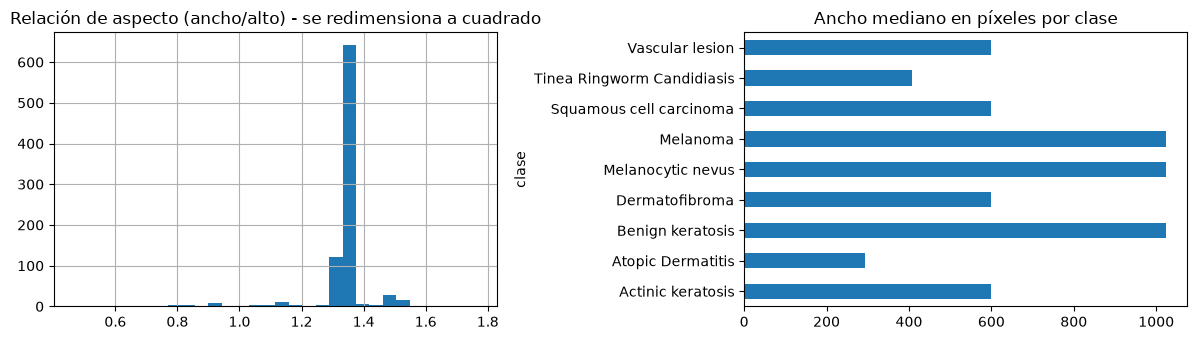

In [3]:
# 1.1 Clases y carpeta de origen
display(pd.crosstab(df["clase"], df["carpeta"], margins=True))
# 1.2 Resoluciones: ¿son todas iguales? ¿dependen de la clase?
print("Resoluciones más frecuentes:"); display(df["res"].value_counts().head(8).to_frame("imágenes").T)
top = df["res"].value_counts().head(5).index
ct = pd.crosstab(df["clase"], df["res"].where(df["res"].isin(top), "otras"), normalize="index").round(2)
print("Fracción de cada clase por resolución:"); display(ct)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
df["aspecto"].hist(bins=30, ax=ax[0]); ax[0].set_title("Relación de aspecto (ancho/alto) - se redimensiona a cuadrado")
(df.groupby("clase")["w"].median()).plot.barh(ax=ax[1]); ax[1].set_title("Ancho mediano en píxeles por clase"); plt.tight_layout(); plt.show()

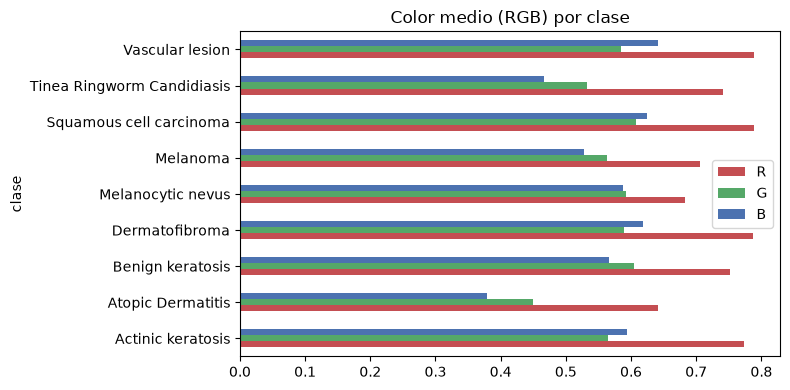

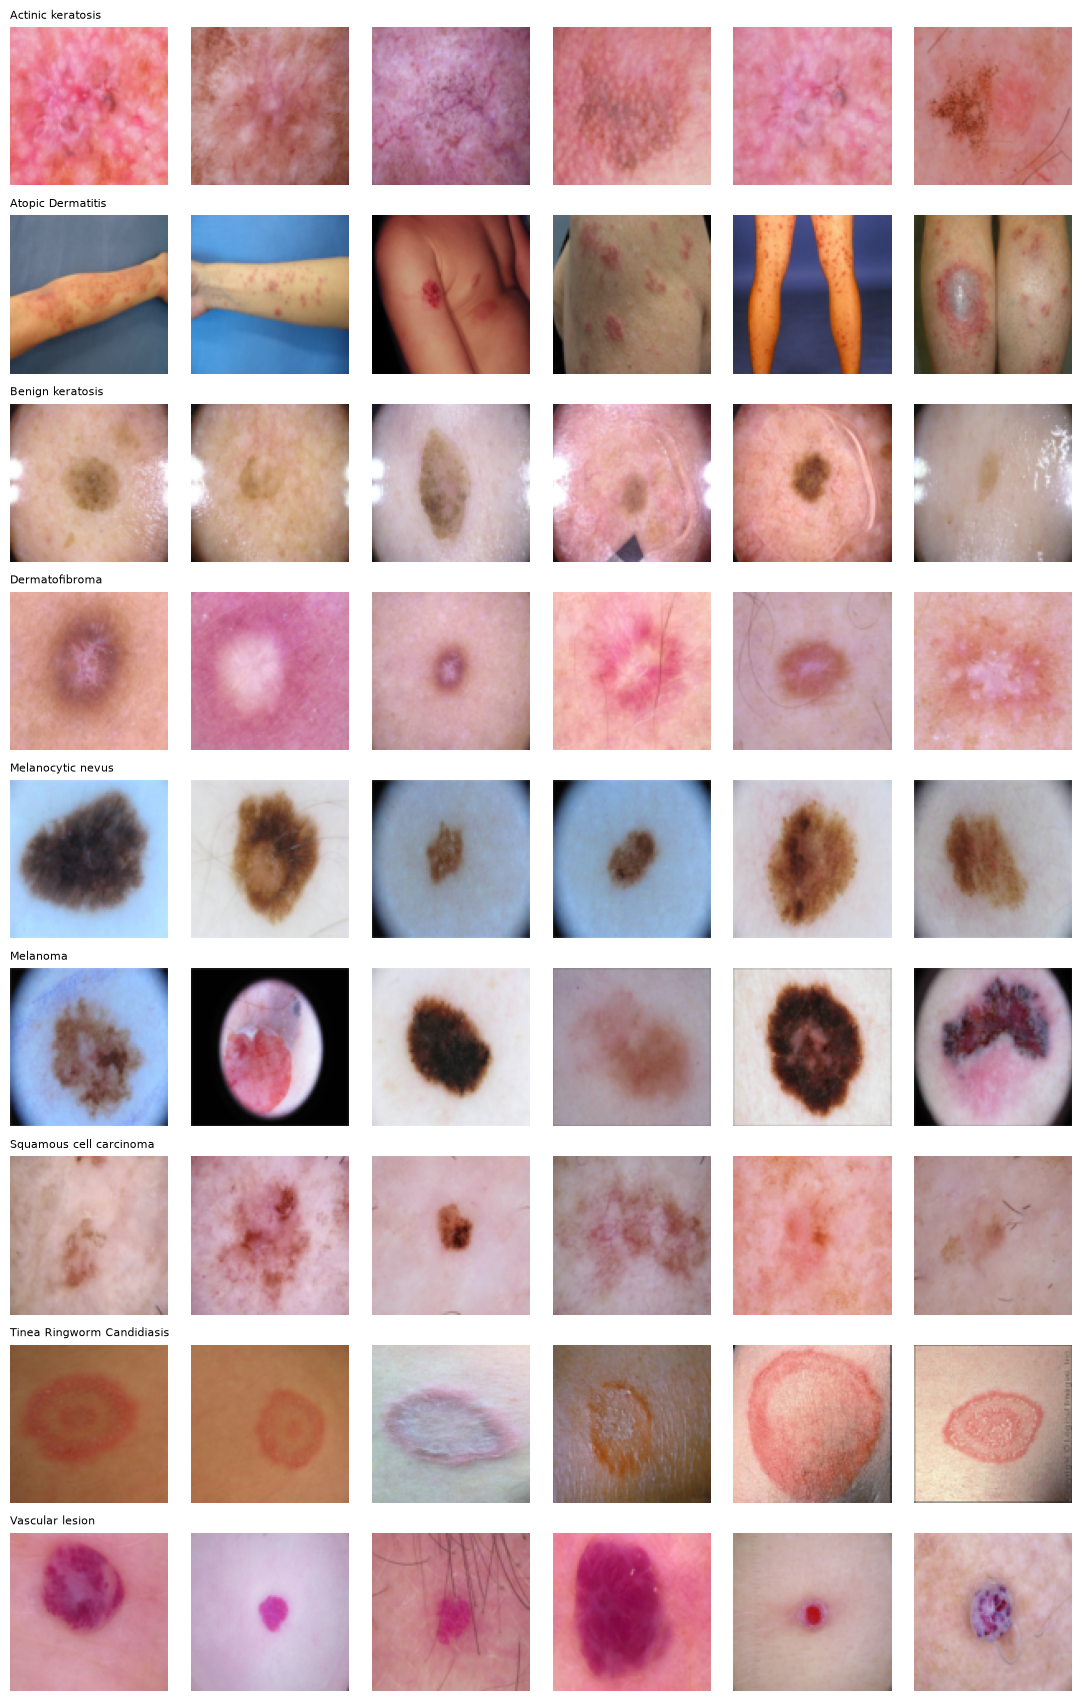

In [4]:
# 1.3 Color medio por clase y ejemplos
mean_rgb = pd.DataFrame(X_U8[32].float().mean((2, 3)).numpy() / 255, columns=["R", "G", "B"]); mean_rgb["clase"] = df["clase"].values
mean_rgb.groupby("clase").mean().plot.barh(color=["#c44e52", "#55a868", "#4c72b0"], figsize=(8, 4), title="Color medio (RGB) por clase"); plt.tight_layout(); plt.show()
fig, axes = plt.subplots(NUM_CLASSES, 6, figsize=(11, 1.9 * NUM_CLASSES))
for ci in range(NUM_CLASSES):
    ids = np.where(labels == ci)[0][:6]
    for j, i in enumerate(ids): axes[ci, j].imshow(X_U8[96][i].permute(1, 2, 0)); axes[ci, j].axis("off")
    axes[ci, 0].set_title(class_names[ci], fontsize=8, loc="left")
plt.tight_layout(); plt.show()

### 1.4 Imágenes duplicadas
El dataset viene con una partición `train/`/`val/` propia. Si una misma imagen está en las dos carpetas, la validación **no mide generalización** (el modelo ya vio esas imágenes). Se buscan duplicados **exactos** (mismo hash MD5 del archivo) y se verifica con un hash perceptual (diferencias entre píxeles vecinos de una miniatura) que no queden **casi-duplicados** (recortes o recompresiones).

In [5]:
g = df.groupby("md5")
dup_groups = [idx for _, idx in g.groups.items() if len(idx) > 1]
cross = [idx for idx in dup_groups if df.loc[idx, "carpeta"].nunique() > 1]
print(f"Grupos de imágenes idénticas: {len(dup_groups)} (de los cuales {len(cross)} están repetidos entre train y val)")
print("Por clase:", df.loc[[idx[0] for idx in dup_groups], "clase"].value_counts().to_dict())
print("Conflictos de etiqueta (misma imagen con clases distintas):", sum(df.loc[idx, "y"].nunique() > 1 for idx in dup_groups))

# hash perceptual: miniatura gris 16x17, bit = pixel > vecino derecho (256 bits); distancia de Hamming
gray = X_U8[32].float().mean(1, keepdim=True)
th_ = F.interpolate(gray, size=(16, 17), mode="area")
H = (th_[..., 1:] > th_[..., :-1]).flatten(1).numpy()
near = []
for i in range(len(H)):
    d = (H[i] != H[i + 1:]).sum(1)
    near += [(i, i + 1 + j) for j in np.where(d <= 8)[0]]
near_not_exact = [(i, j) for i, j in near if df.loc[i, "md5"] != df.loc[j, "md5"]]
print(f"Pares con hash perceptual casi igual (<=8 bits de 256): {len(near)} | de ellos NO idénticos por MD5: {len(near_not_exact)}")

Grupos de imágenes idénticas: 34 (de los cuales 33 están repetidos entre train y val)
Por clase: {'Atopic Dermatitis': 22, 'Tinea Ringworm Candidiasis': 12}
Conflictos de etiqueta (misma imagen con clases distintas): 0
Pares con hash perceptual casi igual (<=8 bits de 256): 34 | de ellos NO idénticos por MD5: 0


###  OBSERVACIONES DEL EDA
Respondan en pocas líneas, con los números de los outputs de arriba:
**1. ¿Qué tan desbalanceado está el dataset? ¿Qué cambia respecto de la partición original `train`/`val`?**

Al inicio hay 878 imágenes:
7 clases tienen 100
1 clase (Atopic Dermatitis) tiene 102 
1 clase (Tinea Ringworm Candidiasis) tiene 76. 

El desbalance es leve. 
 
La partición original train/val (697/181) no reparte igual a todas las clases. 7 clases estan divididas 80/20 y 1 clase está dividida 81/21 (prácticamente igual). Pero Tinea tiene 56 en train y 20 en val por lo que esta subrepresentada en train y en val pesa lo mismo que el resto. 


**2. ¿Hay clases que se distinguen por resolución, relación de aspecto o color de fondo? ¿Qué riesgo tiene eso para un modelo que ve las imágenes redimensionadas?**

Atopic Dermatitis está toda en 294×222, una resolución que no aparece en ninguna otra clase.
Actinic keratosis, Dermatofibroma, Squamous cell carcinoma y Vascular lesion están todas en 600×450.
Benign keratosis está mayormente en 1024×764 (74 %).
Melanocytic nevus y Melanoma están en su mayoría en 1024×768.
Tinea tiene resoluciones variadas, todas fuera de las cinco más comunes.

En color, Atopic Dermatitis es la clase más oscura y menos azulada, seguida por Tinea. 

El riesgo está en que el modelo aprenda a reconocer de que fuente viene la foto en lugar de la lesión en sí. Esto puede aumentar la accuracy de algunas clases sin que el modelo aprenda nada sobre la lesión en si. 


**3. ¿Qué duplicados encontraron, en qué clases y por qué importan para la validación? ¿Qué hubiera pasado con la `val_acc` si no los eliminaran?**

Hay 34 grupos de pares de imágenes idénticas:
-22 en Atopic Dermatitis
-12 en Tinea 

33 de esos pares están repartidos entre train y val. 

Importan porque la validación tiene que medir cómo le va al modelo con imágenes que nunca vio. Si no se eliminaran, en esas dos clases buena parte de la validación serían imágenes que el modelo ya vio en train ( Atopic casi todas), y la `val_acc` saldría inflada. 

## 2. Eliminación de duplicados y split estratificado
- Se **elimina una copia de cada imagen duplicada** (se conserva una sola por grupo de MD5).
- Se juntan **todas** las imágenes que quedan (la partición original no sirve: tenía repetidas y no tenía test) y se hace un split **estratificado 60/20/20** con semilla fija. El test no se toca hasta la sección 8.
- Se calcula la **normalización** (media y desvío por canal) **solo con train**.

In [6]:
keep = df.groupby("md5").head(1).index.values            # una imagen por hash
print(f"Imágenes totales: {len(df)} -> sin duplicados: {len(keep)} (se eliminaron {len(df) - len(keep)})")
idx_tr, idx_tmp = train_test_split(keep, test_size=0.4, stratify=labels[keep], random_state=SEED_SPLIT)
idx_va, idx_te  = train_test_split(idx_tmp, test_size=0.5, stratify=labels[idx_tmp], random_state=SEED_SPLIT)
print(f"train {len(idx_tr)} | val {len(idx_va)} | test {len(idx_te)}")
print(pd.DataFrame({"train": pd.Series(df.loc[idx_tr, "clase"]).value_counts(), "val": pd.Series(df.loc[idx_va, "clase"]).value_counts(),
                    "test": pd.Series(df.loc[idx_te, "clase"]).value_counts()}).to_string())
assert not (set(df.loc[idx_tr, "md5"]) & set(df.loc[idx_va, "md5"])) and not (set(df.loc[idx_tr, "md5"]) & set(df.loc[idx_te, "md5"])) and not (set(df.loc[idx_va, "md5"]) & set(df.loc[idx_te, "md5"]))
STATS = {}
for s in SIZES:
    xt = X_U8[s][idx_tr].float() / 255
    STATS[s] = (xt.mean((0, 2, 3)).view(1, 3, 1, 1), xt.std((0, 2, 3)).view(1, 3, 1, 1))
print("mean/std por canal (64px, solo train):", STATS[64][0].flatten().numpy().round(3), STATS[64][1].flatten().numpy().round(3))

Imágenes totales: 878 -> sin duplicados: 844 (se eliminaron 34)
train 506 | val 169 | test 169
                            train  val  test
clase                                       
Actinic keratosis              60   20    20
Atopic Dermatitis              48   16    16
Benign keratosis               60   20    20
Dermatofibroma                 60   20    20
Melanocytic nevus              60   20    20
Melanoma                       60   20    20
Squamous cell carcinoma        60   20    20
Tinea Ringworm Candidiasis     38   13    13
Vascular lesion                60   20    20
mean/std por canal (64px, solo train): [0.743 0.572 0.565] [0.162 0.164 0.186]


## 3. Data augmentation a mano (solo sobre train, después del split)
No se usa ninguna librería de augmentation: las transformaciones están escritas con operaciones de tensores. Cada imagen de **train** se complementa con `AUG_COPIES` copias transformadas **ya generadas** (se calculan una vez, después del split, así que ninguna copia de una imagen de val/test puede filtrarse a train). Val y test **nunca** se aumentan.

Transformaciones disponibles: flips horizontal/vertical, rotaciones de 90° y brillo/contraste aleatorios. Las lesiones dermatoscópicas no tienen orientación privilegiada, pero el **color** es información diagnóstica.

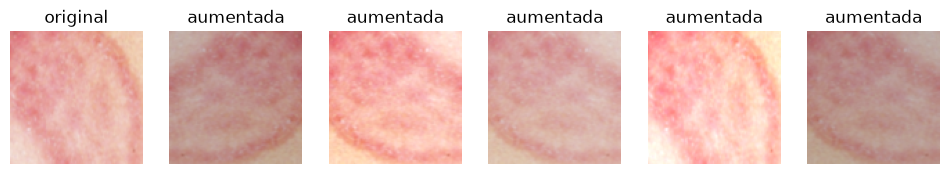

In [7]:
AUGS = {"ninguna": {}, "flips": dict(hflip=True, vflip=True),
        "flips+rot90": dict(hflip=True, vflip=True, rot90=True),
        "flips+rot90+color": dict(hflip=True, vflip=True, rot90=True, color=0.2)}

def augment(x, a):
    # x: tensor float [B,3,H,W] en [0,1]. Cada imagen recibe sus propias transformaciones al azar.
    B = x.shape[0]; x = x.clone()
    if a.get("hflip"):
        m = torch.rand(B) < 0.5; x[m] = x[m].flip(3)
    if a.get("vflip"):
        m = torch.rand(B) < 0.5; x[m] = x[m].flip(2)
    if a.get("rot90"):
        k = torch.randint(0, 4, (B,))
        for kv in (1, 2, 3):
            m = k == kv
            if m.any(): x[m] = torch.rot90(x[m], kv, (2, 3))
    if a.get("color"):
        c = a["color"]
        bri = 1 + (torch.rand(B, 1, 1, 1) * 2 - 1) * c; con = 1 + (torch.rand(B, 1, 1, 1) * 2 - 1) * c
        mu = x.mean((1, 2, 3), keepdim=True); x = ((x - mu) * con + mu) * bri
    return x.clamp(0, 1)

TRAIN_SETS = {}
def train_set(size, aug_name):
    # originales de train + AUG_COPIES copias aumentadas de cada una (generadas una vez, con semilla fija)
    key = (size, aug_name)
    if key not in TRAIN_SETS:
        x0, y0 = X_U8[size][idx_tr], Y[idx_tr]
        if aug_name == "ninguna": TRAIN_SETS[key] = (x0, y0)
        else:
            set_seed(1234); xs, ys = [x0], [y0]
            for _ in range(AUG_COPIES): xs.append((augment(x0.float() / 255, AUGS[aug_name]) * 255).round().to(torch.uint8)); ys.append(y0)
            TRAIN_SETS[key] = (torch.cat(xs), torch.cat(ys))
    return TRAIN_SETS[key]

# Vista de una imagen y sus versiones aumentadas
i0 = idx_tr[0]; base = X_U8[96][i0:i0 + 1].float() / 255; set_seed(3)
fig, ax = plt.subplots(1, 6, figsize=(12, 2.3)); ax[0].imshow(base[0].permute(1, 2, 0)); ax[0].set_title("original")
for k in range(1, 6): ax[k].imshow(augment(base, AUGS["flips+rot90+color"])[0].permute(1, 2, 0)); ax[k].set_title("aumentada")
for a in ax: a.axis("off")
plt.show()

## 4. Modelos y entrenamiento
- **`MLP`**: la referencia (Flatten + 2 capas ocultas).
- **`CNN`**: `n_blocks` bloques `Conv2d → BatchNorm → ReLU → MaxPool(2)` con `filters·2^b` canales, y una cabeza `Flatten → Linear(128) → ReLU → Dropout → Linear(clases)`.
- **`rf_full(...)`** calcula el **campo receptivo** teórico de la última capa convolucional.
- **Entrenamiento**: Adam, early stopping sobre `val_loss` restaurando el mejor estado, tiempo por época medido.

In [8]:
class MLP(nn.Module):
    def __init__(self, size, num_classes=NUM_CLASSES):
        super().__init__()
        self.net = nn.Sequential(nn.Flatten(), nn.Linear(3 * size * size, 512), nn.ReLU(),
                                 nn.Linear(512, 128), nn.ReLU(), nn.Linear(128, num_classes))
    def forward(self, x): return self.net(x)

class CNN(nn.Module):
    def __init__(self, size, n_blocks=3, filters=16, kernel=3, use_bn=True, dropout=0.2, num_classes=NUM_CLASSES):
        super().__init__()
        layers, cin = [], 3
        for b in range(n_blocks):
            cout = filters * 2 ** b
            layers += [nn.Conv2d(cin, cout, kernel, padding=kernel // 2, bias=not use_bn)]
            if use_bn: layers += [nn.BatchNorm2d(cout)]
            layers += [nn.ReLU(), nn.MaxPool2d(2)]
            cin = cout
        self.features = nn.Sequential(*layers)
        fs = size // 2 ** n_blocks                       # lado del mapa de activación después de los n_blocks pooling
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(cin * fs * fs, 128), nn.ReLU(), nn.Dropout(dropout), nn.Linear(128, num_classes))
    def forward(self, x): return self.head(self.features(x))

def rf_full(n_blocks, kernel):
    # campo receptivo de la última conv: cada conv suma (k-1)*salto; cada maxpool(2) suma 1*salto y duplica el salto
    r, j = 1, 1
    for b in range(n_blocks):
        r += (kernel - 1) * j
        if b < n_blocks - 1: r += 1 * j; j *= 2
    return r
def n_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

def norm_batch(x_u8, size):
    mu, sd = STATS[size]; return ((x_u8.float() / 255 - mu) / sd).to(device)

def get_eval_batch(size, ids, shift=0):
    x = X_U8[size][ids].float() / 255
    if shift:   # traslación circular aleatoria (solo para medir robustez a traslaciones)
        x = torch.stack([torch.roll(xi, shifts=(int(np.random.randint(-shift, shift + 1)), int(np.random.randint(-shift, shift + 1))), dims=(1, 2)) for xi in x])
    mu, sd = STATS[size]; return ((x - mu) / sd).to(device), Y[ids].to(device)

@torch.no_grad()
def evaluate(model, ids, size, shift=0):
    model.eval(); L, P = 0.0, []
    for i in range(0, len(ids), 256):
        xb, yb = get_eval_batch(size, ids[i:i + 256], shift)
        out = model(xb); L += F.cross_entropy(out, yb, reduction="sum").item(); P.append(out.argmax(1).cpu())
    P = torch.cat(P).numpy()
    return L / len(ids), accuracy_score(labels[ids], P), P

def make_model(cfg):
    if cfg["model"] == "mlp": return MLP(cfg["size"])
    return CNN(cfg["size"], cfg["n_blocks"], cfg["filters"], cfg["kernel"], cfg.get("use_bn", True), cfg["dropout"])

def fit(cfg, seed):
    set_seed(seed); model = make_model(cfg).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"]); size = cfg["size"]
    Xtr, Ytr = train_set(size, cfg["aug"])
    h = dict(train_loss=[], train_acc=[], val_loss=[], val_acc=[], epoch_time=[])
    best, best_ep, best_state, bad = 1e9, 0, None, 0
    for ep in range(MAX_EPOCHS):
        t0 = time.time(); model.train(); perm = torch.randperm(len(Xtr))
        for i in range(0, len(perm), BATCH):
            ids = perm[i:i + BATCH]
            if len(ids) < 2: continue
            opt.zero_grad(); F.cross_entropy(model(norm_batch(Xtr[ids], size)), Ytr[ids].to(device)).backward(); opt.step()
        if device.type == "cuda": torch.cuda.synchronize()
        h["epoch_time"].append(time.time() - t0)
        trl, tra, _ = evaluate(model, idx_tr, size)       # train ORIGINAL en modo eval (sin dropout ni copias aumentadas)
        vl, va, _ = evaluate(model, idx_va, size)
        h["train_loss"].append(trl); h["train_acc"].append(tra); h["val_loss"].append(vl); h["val_acc"].append(va)
        if vl < best - 1e-4: best, best_ep, best_state, bad = vl, ep, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= PATIENCE: break
    model.load_state_dict(best_state)
    h.update(best_epoch=best_ep + 1, n_epochs=len(h["val_loss"]), n_params=n_params(model))
    return model, h

def run(cfg, seeds=SEEDS):
    # entrena la config con varias semillas y resume (media ± desvío)
    ms, hs = [], []
    for s in seeds:
        m, h = fit(cfg, s); ms.append(m); hs.append(h)
    be = [h["best_epoch"] - 1 for h in hs]
    va = [h["val_acc"][e] for h, e in zip(hs, be)]
    r = dict(val_acc=np.mean(va), val_acc_std=np.std(va), train_acc=np.mean([h["train_acc"][e] for h, e in zip(hs, be)]),
             val_loss=np.mean([min(h["val_loss"]) for h in hs]), best_epoch=np.mean([h["best_epoch"] for h in hs]),
             t_epoca_s=np.mean([np.mean(h["epoch_time"]) for h in hs]), t_total_s=np.mean([sum(h["epoch_time"]) for h in hs]), params=hs[0]["n_params"])
    r["brecha"] = r["train_acc"] - r["val_acc"]
    return r, ms, hs

BASE = dict(model="cnn", size=64, n_blocks=3, filters=16, kernel=3, dropout=0.2, lr=3e-3, aug="ninguna")
print("Parámetros CNN base (64px):", n_params(CNN(64)), "| MLP (64px):", n_params(MLP(64)), "| campo receptivo CNN base:", rf_full(3, 3), "px")

Parámetros CNN base (64px): 549273 | MLP (64px): 6358793 | campo receptivo CNN base: 18 px


### 4.1 Cómo se transforma una imagen dentro de la CNN
La tabla muestra, capa por capa, la **forma de la salida** `(canales, alto, ancho)` y la **cantidad de parámetros** de la CNN base con una imagen de 64×64.

In [9]:
def trace(model, size):
    model.eval(); x = torch.zeros(1, 3, size, size); rows = []
    for i, l in enumerate(list(model.features) + list(model.head)):
        x = l(x); rows.append(dict(capa=i, tipo=l.__class__.__name__, detalle=str(l)[:46], salida=tuple(x.shape[1:]), params=sum(p.numel() for p in l.parameters())))
    return pd.DataFrame(rows)
tr = trace(CNN(64), 64); display(tr); print("Total de parámetros:", tr["params"].sum())

,capa,tipo,detalle,salida,params
0,0,Conv2d,"Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1","(16, 64, 64)",432
1,1,BatchNorm2d,"BatchNorm2d(16, eps=1e-05, momentum=0.1, affin","(16, 64, 64)",32
2,2,ReLU,ReLU(),"(16, 64, 64)",0
3,3,MaxPool2d,"MaxPool2d(kernel_size=2, stride=2, padding=0,","(16, 32, 32)",0
4,4,Conv2d,"Conv2d(16, 32, kernel_size=(3, 3), stride=(1,","(32, 32, 32)",4608
5,5,BatchNorm2d,"BatchNorm2d(32, eps=1e-05, momentum=0.1, affin","(32, 32, 32)",64
6,6,ReLU,ReLU(),"(32, 32, 32)",0
7,7,MaxPool2d,"MaxPool2d(kernel_size=2, stride=2, padding=0,","(32, 16, 16)",0
8,8,Conv2d,"Conv2d(32, 64, kernel_size=(3, 3), stride=(1,","(64, 16, 16)",18432
9,9,BatchNorm2d,"BatchNorm2d(64, eps=1e-05, momentum=0.1, affin","(64, 16, 16)",128


Total de parámetros: 549273


###  EXPLICÁ EL CÓDIGO CONVOLUCIONAL
Con la clase `CNN` y la tabla de arriba, expliquen con sus palabras (y verificando con los números de la tabla):
**1. **`padding=kernel // 2`**: ¿qué pasa con el alto y el ancho al aplicar la convolución? ¿Qué pasaría con `padding=0`? ¿Cómo se ve en la tabla?**

La convolución con kernel k sin relleno solo puede centrarse en los píxeles que tienen k / 2 vecinos de cada lado. 

Con k = 3 y padding = 3 // 2 = 1  queda 64 + 2 − 3 + 1 = 64, es decir, la convolución no cambia el alto ni el ancho, solo la cantidad de canales. 

En la tabla se ve por ejemplo  en la capa 0, que pasa de (3, 64, 64) a (16, 64, 64)
 
Con padding=0 no se agrega relleno y cada convolución recortaría 2 píxeles.  El mapa final sería de 6×6 en vez de 8×8 y además se perdería información del borde de la imagen. 

**2. **`MaxPool2d(2)`**: ¿qué hace con la forma de salida y qué información conserva? ¿Qué relación tiene con `fs = size // 2 ** n_blocks`?**

MaxPool2d(2) divide cada mapa en ventanas de 2×2 que no se superponen y se queda con el valor máximo de cada una. 

El alto y el ancho se reducen a la mitad y la cantidad de canales no cambia. La capa no tiene parámetros (en la tabla: (16, 64, 64) → (16, 32, 32), con 0 parámetros. 

Conserva la rta más fuerte de cada filtro en esa zona. 
Como cada bloque tiene un pooling y la convolución no cambia el tamaño (punto 1), después de `n_blocks` bloques el lado queda dividido por 2^n_blocks: `fs = 64 // 2**3 = 8`, que es el (64, 8, 8) de la capa 11.


**3. **Parámetros:** calculen a mano cuántos parámetros tiene la segunda `Conv2d` (16 → 32 canales, kernel 3) y la primera `Linear` de la cabeza. Verifiquen con la tabla. ¿Cuál de las dos domina el total y por qué?**

Segunda convolución Conv2d 
Recibe 16 canales de 32x32. Canales de entrada x alto_kernel x ancho_kernel = 16x3x3= 144
Se necesitan 32 canales de salida. 144x32 = 4608. 
Es el valor que se ve en la tabla. 


Primera Linear
La salida anterior son 64 canales de 8x8. Flatten acomoda esos números en una sola fila. 64x8x8 = 4096 
Tiene 128 neuronas. Cada una calcula la suma ponderada de todos los valores de entrada y le suma un sesgo. 
Parámetros= 4096x128 + 128 = 524416


**4. **`bias=not use_bn`:** ¿por qué la convolución no necesita sesgo cuando le sigue una BatchNorm?**

La convolución calcula en cada posición una suma ponderada. Generalmente a ese número se le suma el bias o sesgo. Hay uno por canal de salida. La capa que viene después de la convolución es "BatchNorm". Para cada canal toma todos los valores que salieron en el batch, calcula media, desvio y lo normaliza. 

A cada valor del canal se le suma el mismo sesgo , así que en vez de x llega x + sesgo . Si a todos los valores de un grupo se le suma el sesgo, su promedio también sube exactamente ese valor: la nueva media es μ + sesgo . Cuando la BatchNorm resta la media:
(x + b) − (μ + b) = x − μ. El sesgo desaparece.

**5. **`filters * 2 ** b`:** ¿por qué se duplican los canales mientras se reduce la resolución a la mitad?**

Bloque 0: 16x2^0 = 16 canales
Bloque 1: 16x2^1 = 32 canales
Bloque 2: 16x2^2 = 64 canales

Al mismo tiempo MaxPool que mencionamos antes divide la cantidad de posiciones por 4 (2 por lado). Al duplicar los canales la información solo se reduce a la mitad. 

**6. **`rf_full`:** reproduzcan a mano el campo receptivo de 18 px para 3 bloques con kernel 3 y expliquen qué significa ese número respecto de una imagen de 64 px.**

El campo receptivo es el tamaño de la zona de la imagen que ve una neurona. Si un píxel queda fuera de esa zona, cambiarlo no afecta en nada a esa neurona. 
1 convolución de 3: cada valor de la salida ve 3 posiciones de la entrada. Entonces ve 3 píxeles
2 convoluciones de 3: un valor de la segunda capa mira 3 posiciones de la primera. Cada una de esas posiciones ve 3 píxeles, pero se superponen porque las vecinas están corridas un píxel. En total ven 3 + 1 + 1 = 5 píxeles. Cada convolución nueva agrega k − 1 = 2 píxeles.
MaxPool después agrega un salto (j)

Así funciona rf_full:
conv: r=r + (k-1) x j
pool: r=r + j, y después j = 2 x j

Definimos r=1 con r la cantidad de píxeles que se ven
Definimos j=1 con j la distancia entre posiciones vecinas

Bloque 1: 
convolución1: r= 1+2x1=3
pool1: r=3+1=4 y j=2

Bloque 2: 
convolución2: r= 4+2x2=8
pool: r=10 y j=4

Bloque 3: 
Convolución3: r=10+2x4= 18

Resultado 18px. Cada valor de la última convolución ve como mucho un cuadrado de 18 × 18 píxeles de una imagen de 64 × 64.





### 4.2 Chequeo rápido: el modelo aprende
Se entrena la CNN base con una semilla y se grafican curvas. Sirve para verificar que el pipeline funciona antes de correr los experimentos.

mejor época 8 | val_acc 0.592 | train_acc 0.698 | 0.83 s/época | total 39s


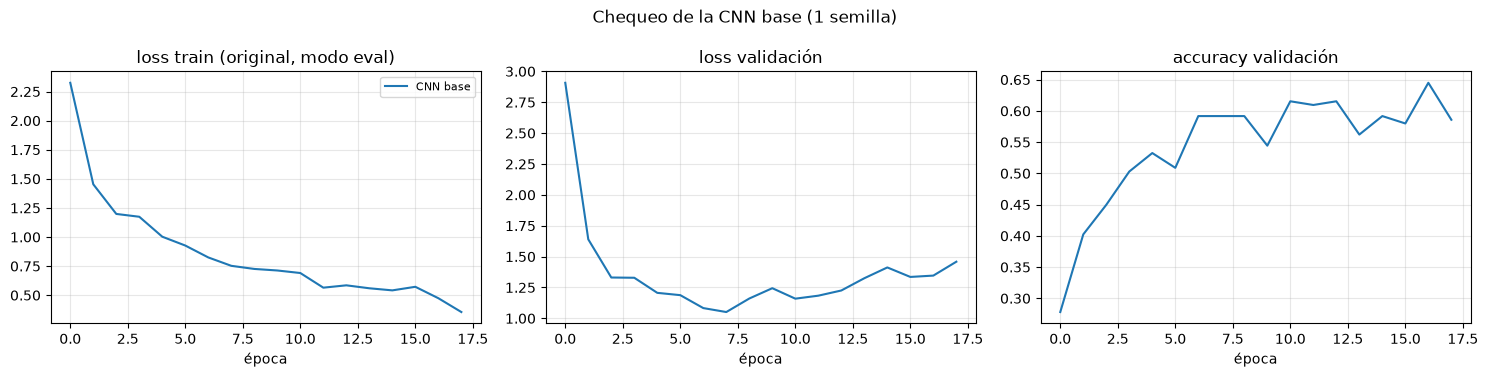

In [10]:
def plot_curves(hists, title):
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
    for name, h in hists.items():
        ax[0].plot(h["train_loss"], label=name); ax[1].plot(h["val_loss"], label=name); ax[2].plot(h["val_acc"], label=name)
    for a, t in zip(ax, ["loss train (original, modo eval)", "loss validación", "accuracy validación"]): a.set_title(t); a.set_xlabel("época"); a.grid(alpha=.3)
    ax[0].legend(fontsize=8); fig.suptitle(title); plt.tight_layout(); plt.show()
t0 = time.time(); _, h = fit(BASE, 0)
print(f"mejor época {h['best_epoch']} | val_acc {h['val_acc'][h['best_epoch']-1]:.3f} | train_acc {h['train_acc'][h['best_epoch']-1]:.3f} | {np.mean(h['epoch_time']):.2f} s/época | total {time.time()-t0:.0f}s")
plot_curves({"CNN base": h}, "Chequeo de la CNN base (1 semilla)")

## 5. De la MLP a la CNN
Misma resolución, mismo split, mismo criterio de parada, 3 semillas. Además de val_acc se mide:
- **Parámetros y tiempo por época.**
- **Robustez a traslaciones**: se evalúa el modelo ya entrenado sobre validación con imágenes **trasladadas** al azar hasta ±`SHIFT` px (la convolución es equivariante a traslaciones y con pooling aproximadamente invariante; la MLP no tiene esa propiedad).

,modelo,params,val_acc,std,train_acc,brecha,mejor_epoca,t_epoca_s,val_acc_trasladada,caida_por_traslacion
0,MLP 32px,1640201,0.4892,0.0056,0.6970,0.2078,4.0000,0.1824,0.4116,0.0776
1,MLP 64px,6358793,0.4911,0.0290,0.6976,0.2065,6.6667,0.5912,0.4109,0.0802
2,CNN 32px,156057,0.6272,0.0145,0.8491,0.2219,10.6667,0.3032,0.5759,0.0513
3,CNN 64px,549273,0.5858,0.0048,0.7398,0.1540,8.6667,0.8338,0.5378,0.0480


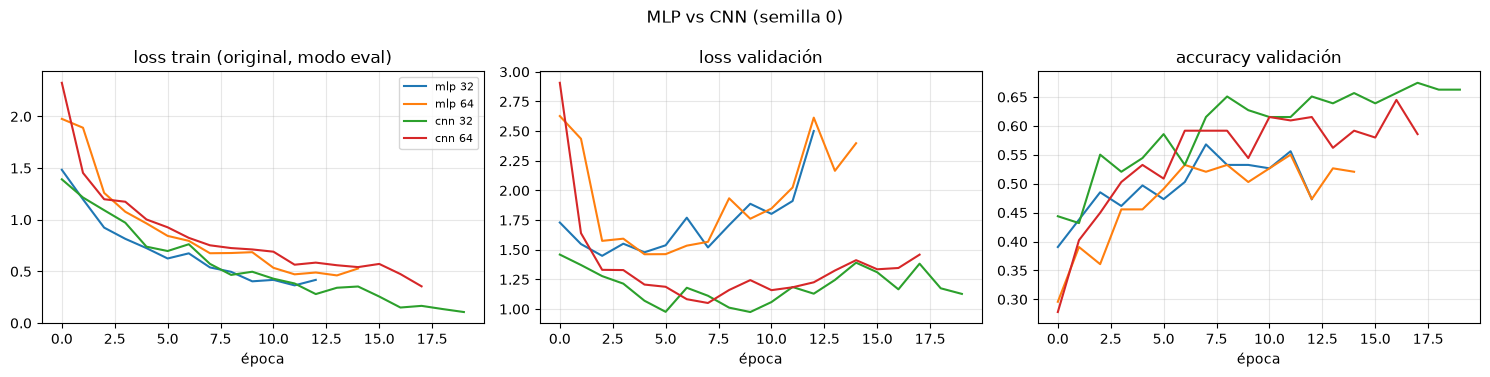

Referencia: azar = 0.111 | error estándar binomial de un accuracy ~0.5 con 169 imágenes de val = 0.038


In [11]:
SHIFT = {32: 4, 64: 8}
rows, store = [], {}
for model_name, size in [("mlp", 32), ("mlp", 64), ("cnn", 32), ("cnn", 64)]:
    cfg = {**BASE, "model": model_name, "size": size}
    r, ms, hs = run(cfg)
    clean = [evaluate(m, idx_va, size)[1] for m in ms]; shifted = [np.mean([evaluate(m, idx_va, size, shift=SHIFT[size])[1] for _ in range(3)]) for m in ms]
    rows.append(dict(modelo=f"{model_name.upper()} {size}px", params=r["params"], val_acc=r["val_acc"], std=r["val_acc_std"], train_acc=r["train_acc"],
                     brecha=r["brecha"], mejor_epoca=r["best_epoch"], t_epoca_s=r["t_epoca_s"],
                     val_acc_trasladada=np.mean(shifted), caida_por_traslacion=np.mean(clean) - np.mean(shifted)))
    store[f"{model_name} {size}"] = hs[0]
display(pd.DataFrame(rows).round(4))
plot_curves(store, "MLP vs CNN (semilla 0)")
print(f"Referencia: azar = {1/NUM_CLASSES:.3f} | error estándar binomial de un accuracy ~0.5 con {len(idx_va)} imágenes de val = {np.sqrt(.25/len(idx_va)):.3f}")

### PREGUNTAS MLP A CNN
**1. Compará MLP y CNN en **parámetros, val_acc (± desvío), brecha train-val, tiempo por época y época de convergencia**. ¿La diferencia de val_acc supera el ruido entre semillas y el error estándar de la validación?**

Parámetros:
A 32 px la MLP tiene 1640201 y la CNN 156057 (10 veces menos)
A 64 px, la MLP tiene 6358793 y la CNN 549.273  (11 veces menos)

Val_acc:
La CNN es mejor en las dos resoluciones.

brecha train val:
A 32 px la brecha es casi igual con 0,222 la CNN contra 0,208 la MLP.  
A 64 px la CNN tiene una brecha más chica: 0,154 contra 0,207.

Epoca de convergencia:
La MLP se frena en la época 4 (32 px) y 6,7 (64 px) en promedio. La CNN sigue mejorando hasta la época 10,7 (32 px) y 8,7 (64 px).

Tiempo por epoca:
La CNN es más lenta por época aunque tenga 10 veces menos parámetros: 0,30 s contra 0,18 s a 32 px, y 0,83 s contra 0,59 s a 64 px.

La MLP usa cada peso una sola vez por imagen. La convolución, en cambio, aplica el mismo filtro en todas las posiciones de la imagen, así que reutiliza sus pocos pesos miles de veces y termina haciendo más cuentas. Como además converge más tarde, también tarda más en total.

val_acc supera el ruido entre semillas. La diferencia más chica, 9,5 puntos a 64 px, es más de 3 veces el desvío más grande de la tabla
val_acc supera el error estandar de la validacion. 

**2. ¿Por qué la MLP necesita tantos más parámetros? Calculá a mano cuántos parámetros tiene la primera capa de la MLP a 32 y a 64 px y explicá qué pasaría a 224 px. ¿Qué propiedades de la convolución (pesos compartidos, conectividad local) cambian ese número?**

La primera capa de la MLP es una Linear. La imagen entra aplanada con todos los píxeles de los 3 canales puestos en una sola fila.

pesos por neurona = cantidad de valores de la imagen = 3 × alto × ancho
parámetros de la capa = (3 × alto × ancho) × 512 pesos + 512 sesgos (uno por neurona)

A 32 px:
La imagen tiene 3 x 32 x 32 = 3072 valores.
Pesos: 3072 x 512 = 1572864. Sesgos: 512. Total: 1573376

A 64 px:
La imagen tiene 3 x 64 x 64 = 12288 valores.
Pesos: 12288 x 512 = 6291456. Sesgos: 512. Total: 6291968

A 224 px la imagen tiene 3 × 224 × 224 = 150528 valores.
150528 × 512 + 512 = 77070848 parámetros. El modelo sería muy costoso.

La convolución reduce ese número mediante conectividad local y pesos compartidos. 

**3. Mirá la **caída por traslación**: ¿cuál de los dos modelos se degrada menos y por qué? ¿Es coherente con la teoría de equivarianza/invarianza, o el ruido no permite concluir?**

El que se degrada menos es la CNN. La convolución es equivariante a traslaciones: como el mismo filtro se aplica en todas las posiciones, si la lesión se corre, el mapa de activación se corre igual, pero los patrones se siguen detectando.

En la MLP cada píxel tiene su propio peso, así que si la imagen se corre, los mismos píxeles caen sobre pesos distintos y para la red es como ver una imagen nueva

La diferencia entre las dos caídas, unos 3 puntos, es menor que el error estándar de la validación (±0,038), así que no se puede afirmar con total seguridad.


**4. ¿Qué rol cumple la normalización de entrada acá (mencionen cómo se calculó) y qué esperarían si no se hiciera?**

Se toman solo las imágenes de train, después del split. Para cada canal (R, G y B) se calculan la media y el desvío de todos sus píxeles, y después a cada imagen (de train, val y test) se le resta esa media y se la divide por ese desvío. Se usa solo train porque val y test tienen que ser imágenes nunca vistas y si su información entrara en la normalización se estaría filtrando algo de ellas.

La normalización deja cada canal centrado en 0 y con una escala parecida para que ningun canal pese más que otro sólo por tener valores más grandes. Si no se hiciera se vería más afectada la MLP ya que CNN hace BatchNorm que normaliza y compensa en parte 

## 6. Decisiones de arquitectura convolucional
Se parte de la CNN base y se cambia **un factor a la vez** (3 semillas cada uno): profundidad, tamaño del kernel, cantidad de filtros y resolución de entrada. Se reporta además el **campo receptivo** teórico y los parámetros (que incluyen la capa `Linear` de la cabeza, cuyo tamaño depende de la resolución y la profundidad).

,variante,campo_receptivo,params,val_acc,val_acc_std,train_acc,brecha,best_epoch,t_epoca_s,t_total_s
0,"base (3 bloques, k=3, 16 filtros, 64px)",18,549273,0.5858,0.0048,0.7398,0.1540,8.6667,0.8122,15.1225
1,2 bloques,8,1055001,0.5976,0.0084,0.7200,0.1224,7.6667,0.8198,14.4713
2,4 bloques,38,361113,0.6509,0.0211,0.8267,0.1759,15.6667,1.0958,28.1157
3,kernel 5,32,591001,0.6292,0.0101,0.8762,0.2470,21.3333,1.1788,37.0613
4,kernel 7,46,653593,0.6075,0.0311,0.7661,0.1586,18.3333,1.6222,46.0664
5,8 filtros,18,269521,0.6469,0.0295,0.8590,0.2121,10.3333,0.4374,8.8979
6,32 filtros,18,1143337,0.6036,0.0000,0.7773,0.1738,14.6667,2.0841,51.4099
7,32 px,18,156057,0.6272,0.0145,0.8491,0.2219,10.6667,0.2942,6.0814
8,96 px,18,1204633,0.6193,0.0243,0.7523,0.1330,13.0000,2.0706,47.9026


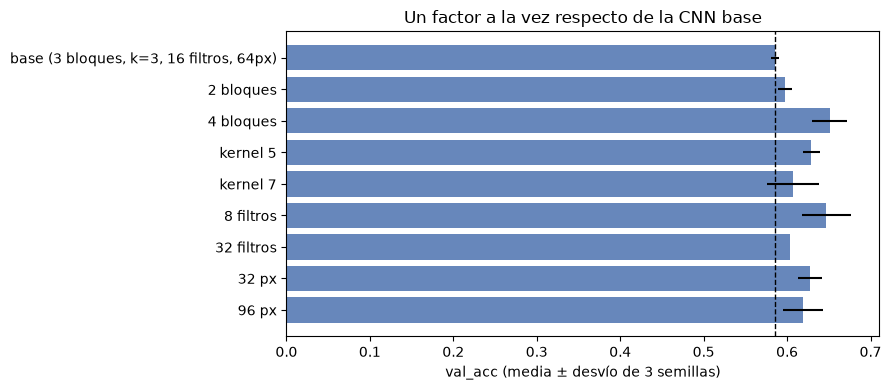

In [12]:
ARCH_VARIANTS = {
    "base (3 bloques, k=3, 16 filtros, 64px)": {},
    "2 bloques": dict(n_blocks=2), "4 bloques": dict(n_blocks=4),
    "kernel 5": dict(kernel=5), "kernel 7": dict(kernel=7),
    "8 filtros": dict(filters=8), "32 filtros": dict(filters=32),
    "32 px": dict(size=32), "96 px": dict(size=96),
}
rows, arch_cfgs, arch_hist = [], {}, {}
for name, delta in ARCH_VARIANTS.items():
    cfg = {**BASE, **delta}; r, ms, hs = run(cfg)
    rows.append(dict(variante=name, campo_receptivo=rf_full(cfg["n_blocks"], cfg["kernel"]), **r)); arch_cfgs[name] = cfg; arch_hist[name] = hs[0]
tab_arch = pd.DataFrame(rows)
display(tab_arch[["variante", "campo_receptivo", "params", "val_acc", "val_acc_std", "train_acc", "brecha", "best_epoch", "t_epoca_s", "t_total_s"]].round(4))
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(tab_arch["variante"], tab_arch["val_acc"], xerr=tab_arch["val_acc_std"], color="#4c72b0", alpha=.85); ax.invert_yaxis()
ax.axvline(tab_arch["val_acc"].iloc[0], color="k", ls="--", lw=1); ax.set_xlabel("val_acc (media ± desvío de 3 semillas)"); ax.set_title("Un factor a la vez respecto de la CNN base"); plt.tight_layout(); plt.show()

### ANÁLISIS 2 - Arquitectura convolucional
**1. ¿Qué factores cambian la val_acc **más allá del ruido entre semillas** (desvío de la tabla) y cuáles no? Sean explícitos sobre qué diferencias son pequeñas respecto del ruido.**

Agregar profundidad (4 bloques), usar kernel 5 o bajar a 32px mejoran respecto de la base más allá del ruido entre semillas, pero ninguna mejora es lo bastante grande para ser segura con una validación tan chica. Las demás diferencias (2 bloques, kernel 7, 32 filtros, 96 px) son pequeñas comparadas con el ruido.

**2. **Profundidad y kernel:** relacionen el campo receptivo con el tamaño de la imagen y con lo que se quiere detectar en una lesión (bordes, texturas, asimetría global). ¿Qué esperaban de agregar bloques o agrandar el kernel y qué se observó? Comparen costo (parámetros y tiempo) vs. ganancia.**

Se podría esperar que al agrandar el campo receptivo, ya sea con más bloques o con kernels más grandes se mejorara la accuracy ya que las las convoluciones podrían captar formas más grandes de la lesión. 

La mejor variante fue 4 bloques. Kernel 5 y 7 tienen una diferencia dentro del ruido entre sí, por lo que no se podría decir que agrandar el campo mejoró en este caso. Con 2 bloques la acc es muy parecida a la de la base. Aumentar el campo ayuda, pero lo que mejor funcionó fue agregar profundidad y no agrandar el kernel.

4 bloques, además de tener mejor accuracy tiene menos parámetros que la base aunque su tiempo de entrenamiento es de casi el doble. 
El kernel 5 tiene levemente más parámetros pero el tiempo de entrenamiento aumenta 2,5 veces.
El kernel 7  tiene muchos más parámetros y 3 veces el tiempo total, sin notar una ganancia que supere al ruido en comparación al kernel más chico. 
2 bloques tiene casi el doble de parámetros que la base y rinde de manera similar, por lo que no conviene. 

Conclusión: para que la red vea más de la lesión, conviene agregar bloques en vez de agrandar el kernel. Agregar un bloque amplía el campo receptivo, reduce parámetros y cuesta menos tiempo que usar kernels grandes.

**3. **Resolución de entrada (32/64/96):** ¿cómo cambia la cantidad de parámetros de la capa `Linear` de la cabeza y por qué? ¿Qué se gana (detalle disponible) y qué se pierde (cómputo, campo receptivo relativo a la imagen)? Con tan pocas imágenes por clase, ¿qué límite tiene este experimento?**

La linear recibe el mapa final aplanado. Cada mapa mide la imagen dividida por 8 de lado con 64 canales. 
32px: mapa de 4×4:  64x4x4 = 1024 entradas -> 1024x128+128 = 131200 parámetros
64px: mapa de 8x8: 4096 entradas -> 524416 parámetros
96px: mapa de 12x12: 9216 entradas -> 1179776 parámetros

Crece con relación al cuadrado de la resolución. Si un lado se duplica linear cuadruplica sus parámetros. Las convoluciones no cambian, porque sus pesos son compartidos. 

Se gana más detalle ya que a mayor resolución la imagen conserva bordes más finos y texturas. 
Se pierde cómputo y campo perceptivo relativo. La red es la misma, así que siempre ve 18 px, pero esos 18 px son una parte cada vez más chica de la imagen

Se observó que 32px fue la mejor (0,627 ± 0,015), seguida por 96px (0,619 ± 0,024) y 64px la peor (0,586 ± 0,005). El experimento está limitado por la cantidad de imágenes y que sólo se cambió la resolución pero no los bloques. 

**4. ¿Qué no se puede concluir con un diseño de "un factor a la vez" y 3 semillas?**

Cada variante cambia una sola cosa respecto de la base, así que no sabemos qué pasa al cambiar varias juntas. Por ejemplo, 4 bloques y 8 filtros mejoraron cada una por su lado, pero no se probó 4 bloques con 8 filtros.Las mejoras podrían sumarse, no sumarse o incluso empeorar juntas. Lo mismo con la resolución: a 96 px quizás haría falta un bloque más, y esa combinación no está en la tabla.

Además, cada efecto se midió partiendo de una base particular pero no se puede inferir que partiendo de otra red el cambio siga ayudando o empeorando. 


## 7. Data augmentation
Con ~60 imágenes por clase en train, el overfitting es esperable. Se comparan cuatro niveles de augmentation (los de la sección 3) con la CNN base y 3 semillas. En cada caso, **train queda con las imágenes originales más `AUG_COPIES` copias aumentadas de cada una**; val y test no se tocan.

,augmentation,n_train,val_acc,val_acc_std,train_acc,brecha,val_loss,best_epoch,t_epoca_s,t_total_s
0,ninguna,506,0.5858,0.0048,0.7398,0.1540,1.0562,8.6667,0.9069,16.9263
1,flips,1518,0.6252,0.0101,0.7951,0.1699,1.0244,7.3333,2.3841,41.5431
2,flips+rot90,1518,0.6272,0.0167,0.8182,0.1910,1.0501,10.3333,2.3403,47.2541
3,flips+rot90+color,1518,0.6450,0.0365,0.8030,0.1581,1.0662,11.3333,2.1548,46.1887


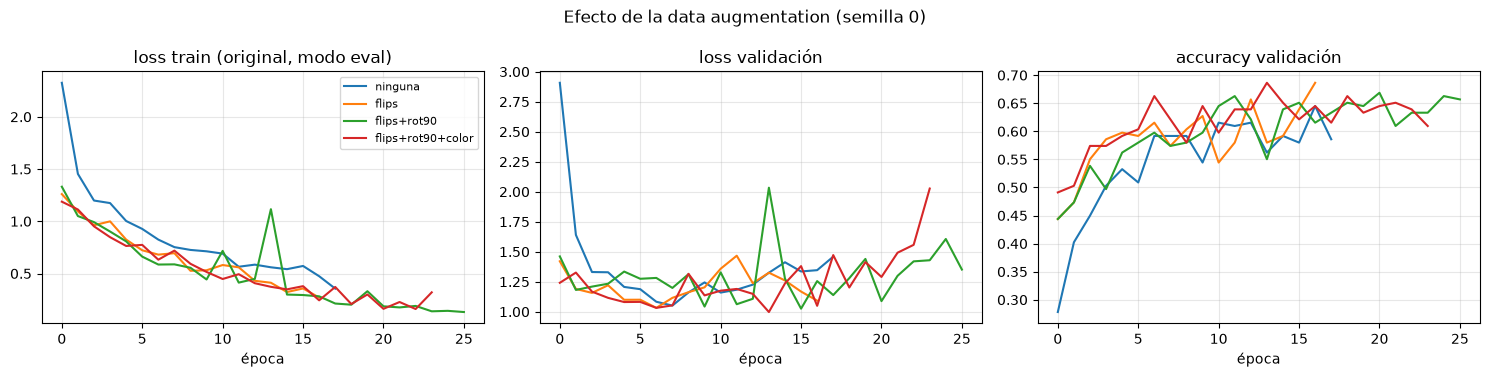

In [13]:
rows, aug_hist = [], {}
for name in AUGS:
    cfg = {**BASE, "aug": name}; r, ms, hs = run(cfg)
    rows.append(dict(augmentation=name, n_train=len(train_set(64, name)[0]), **r)); aug_hist[name] = hs[0]
tab_aug = pd.DataFrame(rows)
display(tab_aug[["augmentation", "n_train", "val_acc", "val_acc_std", "train_acc", "brecha", "val_loss", "best_epoch", "t_epoca_s", "t_total_s"]].round(4))
plot_curves(aug_hist, "Efecto de la data augmentation (semilla 0)")

### TU ANÁLISIS 3 - Overfitting y augmentation
**1. Demostrá el overfitting de la CNN sin augmentation **con números**: brecha train-val, época donde la `val_loss` empieza a subir.**

Sin augmentacion en la mejor época la CNN acierta en promedio el 74,0 % de train y el 58,6 % de validación (media de 3 semillas), una brecha de 15,4 puntos. 

En la semilla 0, la val_loss baja hasta su mínimo de 1,051 en la época 8 y a partir de ahí empieza a subir hasta llegar a  1,459 en la época 18 (para calcular esto agregue un breve código debajo) cuando el early stopping corta el entrenamiento. En ese mismo tramo, la loss de train sigue bajando de 0,753 a 0,355

Que la loss de train baje mientras la de validación sube es la señal típica de overfitting: la red sigue mejorando en las imágenes que ya vio, pero empeora con las nuevas. Por eso el early stopping se queda con los pesos de la época 8.

**2. ¿Qué cambia con cada nivel de augmentation sobre la **brecha**, la `val_loss`, la `val_acc`, la **época de convergencia** y el **tiempo total**? ¿Por qué cada época cuesta más con augmentation? ¿Cuál de las mejoras supera el ruido entre semillas?**

Cada nivel de augmentation agrega 2 copias transformadas por imagen, así que train pasa de 506 a 1518 imágenes.
val_acc mejora con los 3 niveles pasando de 0,586 a 0,625 con flips, a 0,627 con flips + rot90 y a 0,645 con flips + rot90 + color.
val_loss casi no cambia. La brecha no cambia ya que la accuracy del train también sube: la red aprende mejor las dos cosas, así que la diferencia entre ambas no se achica.
La época de convergencia es mayor a mayor nivel de augmentation y el tiempo total también aumenta. Cada época tarda más porque necesita el triple de imágenes. Por eso también se ve en las curvas que los modelos con augmentation arrancan con una val_acc mucho más alta en la época 0 ya que en una sola época hicieron 3 veces más pasos de entrenamiento.

-Flips +3,9 puntos  con un desvío de 0,010 -> superaa el ruido entre semillas por 4 veces
-Flips+ rot90 +4,1 puntos con un desvío de 0,017 -> supera el ruido entre semillas por 2,5 veces
-Flips+rot90+color +5,9 puntos con desvío de 0,037. -> supera el ruido por 1,6 veces. No es suficiente



**3. Discutan desde el dominio (dermatología) qué transformaciones tienen sentido y cuáles podrían **destruir información** (por ejemplo, el color o la escala). ¿Qué otras augmentations probarían?**

Los flips y rotaciones tienen sentido ya que no existe el arriba y abajo. El brillo y contraste deberían tratarse con cuidado ya que los melanomas pueden ser identificados por coloraciones. Se podrían probar rotaciones de ángulos random o desenfoques suaves.

**4. ¿Por qué es importante que la augmentation se haga **después** del split y **solo en train**? ¿Qué pasaría con las métricas si se aumentara antes de dividir?**

Si se aumentara antes de dividir, una imagen y sus copias rotadas o espejadas podrían quedar repartidas entre train, validación y test. Sería el mismo problema de los duplicados en el que el modelo se evaluaría sobre imágenes que son casi iguales a las que vio en train, la val_acc y el test saldrían inflados y habría sesgo 

Val y test no se aumentan porque tienen que representar imágenes reales que va a usar el modelo. 


**5. Compará con lo que vieron en el TP3: ¿qué diferencia hay entre regularizar con dropout/L2 (restricciones sobre los pesos) y con augmentation (más datos sintéticos)?**

El dropout y L2 restringian al modelo penalizando pesos grandes o apagando neuronas al azar. Los dos hacen que memorizar sea más dificil pero no aportan información nueva

La aumentación modifica el lado de los datos. Le muestra al modelo más variedad de imágenes. Hay más conocimiento del dominio en el entrenamiento pero tiene como costo que tarda más. 

In [17]:
h0 = aug_hist["ninguna"]
for ep, (tl, vl) in enumerate(zip(h0["train_loss"], h0["val_loss"]), start=1):
    print(f"época {ep:2d} | loss train {tl:.3f} | loss val {vl:.3f}")
print("mejor época (semilla 0):", h0["best_epoch"])

época  1 | loss train 2.325 | loss val 2.907
época  2 | loss train 1.453 | loss val 1.640
época  3 | loss train 1.198 | loss val 1.331
época  4 | loss train 1.174 | loss val 1.329
época  5 | loss train 1.003 | loss val 1.207
época  6 | loss train 0.927 | loss val 1.188
época  7 | loss train 0.825 | loss val 1.083
época  8 | loss train 0.753 | loss val 1.051
época  9 | loss train 0.726 | loss val 1.161
época 10 | loss train 0.713 | loss val 1.244
época 11 | loss train 0.691 | loss val 1.159
época 12 | loss train 0.565 | loss val 1.184
época 13 | loss train 0.585 | loss val 1.226
época 14 | loss train 0.560 | loss val 1.325
época 15 | loss train 0.542 | loss val 1.412
época 16 | loss train 0.572 | loss val 1.335
época 17 | loss train 0.474 | loss val 1.346
época 18 | loss train 0.355 | loss val 1.459
mejor época (semilla 0): 8


## 8. Elección del modelo final y evaluación en TEST (una sola vez)
Se arma la configuración final tomando, entre las variantes de arquitectura, la de **mejor val_acc media** y, entre las de augmentation, la de **mejor val_acc media** (ambas ya medidas arriba). Se puede forzar otra decisión con `FINAL_OVERRIDE` (justificándola en el análisis). Es una decisión *greedy* de un factor a la vez: no se garantiza que la combinación sea mejor que cada parte.

Luego se entrenan la config final y la MLP de referencia (64 px) con las semillas `SEEDS_FINAL` y se evalúan en test **una única vez**. No se vuelve a tocar nada después de ver estos números.

In [14]:
best_arch = tab_arch.sort_values(["val_acc", "params"], ascending=[False, True]).iloc[0]["variante"]
best_aug  = tab_aug.sort_values("val_acc", ascending=False).iloc[0]["augmentation"]
FINAL_CFG = {**arch_cfgs[best_arch], "aug": best_aug}
FINAL_OVERRIDE = None          # por ejemplo: dict(n_blocks=4, aug="flips+rot90")
if FINAL_OVERRIDE: FINAL_CFG = {**FINAL_CFG, **FINAL_OVERRIDE}
print("Mejor arquitectura (val):", best_arch, "| mejor augmentation (val):", best_aug)
print("Config final:", FINAL_CFG)
rf_, ms_, hs_ = run(FINAL_CFG)
print(f"Config final en validación: val_acc {rf_['val_acc']:.3f} ± {rf_['val_acc_std']:.3f} | brecha {rf_['brecha']:.3f} | mejor época {rf_['best_epoch']:.1f} | {rf_['t_total_s']:.0f}s por entrenamiento")

Mejor arquitectura (val): 4 bloques | mejor augmentation (val): flips+rot90+color
Config final: {'model': 'cnn', 'size': 64, 'n_blocks': 4, 'filters': 16, 'kernel': 3, 'dropout': 0.2, 'lr': 0.003, 'aug': 'flips+rot90+color'}
Config final en validación: val_acc 0.633 ± 0.010 | brecha 0.147 | mejor época 10.0 | 56s por entrenamiento


,modelo,params,test_acc,test_acc_std,test_f1_macro,f1_std,tiempo_entrenamiento_s
0,CNN final,361113,0.6710,0.0096,0.6633,0.0147,45.2585
1,MLP 64px,6358793,0.4899,0.0391,0.4731,0.0450,9.5168


Error estándar binomial del test (169 imágenes): ±0.036 | azar: 0.111
                            precision    recall  f1-score   support

         Actinic keratosis       0.48      0.70      0.57        20
         Atopic Dermatitis       0.82      0.88      0.85        16
          Benign keratosis       0.86      0.90      0.88        20
            Dermatofibroma       0.68      0.65      0.67        20
         Melanocytic nevus       0.65      0.65      0.65        20
                  Melanoma       0.57      0.40      0.47        20
   Squamous cell carcinoma       0.50      0.65      0.57        20
Tinea Ringworm Candidiasis       0.86      0.46      0.60        13
           Vascular lesion       1.00      0.80      0.89        20

                  accuracy                           0.68       169
                 macro avg       0.71      0.68      0.68       169
              weighted avg       0.71      0.68      0.68       169



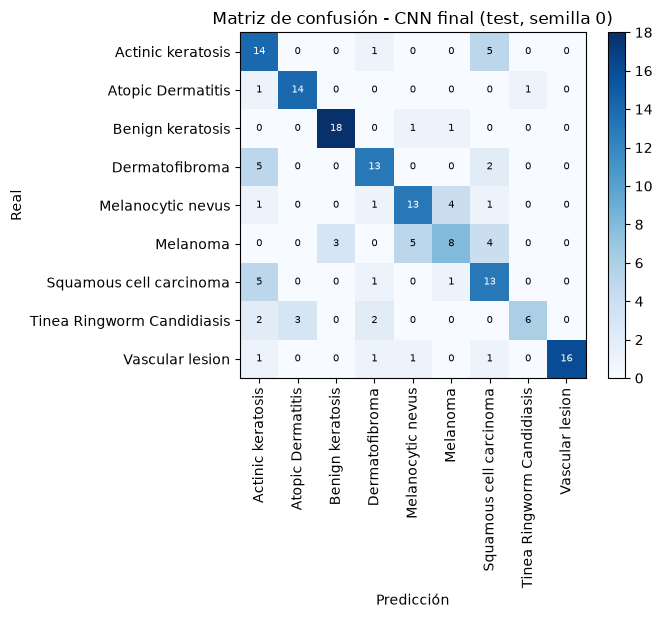

In [15]:
# ---- EVALUACIÓN EN TEST: se ejecuta una sola vez ----
final_rows, final_models, final_preds = [], {}, {}
for name, cfg in [("CNN final", FINAL_CFG), ("MLP 64px", {**BASE, "model": "mlp", "size": 64})]:
    accs, f1s, times = [], [], []
    for s in SEEDS_FINAL:
        m, h = fit(cfg, s); _, a, p = evaluate(m, idx_te, cfg["size"])
        accs.append(a); f1s.append(f1_score(labels[idx_te], p, average="macro")); times.append(sum(h["epoch_time"]))
        if s == SEEDS_FINAL[0]: final_models[name], final_preds[name] = m, p
    final_rows.append(dict(modelo=name, params=h["n_params"], test_acc=np.mean(accs), test_acc_std=np.std(accs), test_f1_macro=np.mean(f1s), f1_std=np.std(f1s), tiempo_entrenamiento_s=np.mean(times)))
final = pd.DataFrame(final_rows); display(final.round(4))
se = np.sqrt(final.loc[0, "test_acc"] * (1 - final.loc[0, "test_acc"]) / len(idx_te))
print(f"Error estándar binomial del test ({len(idx_te)} imágenes): ±{se:.3f} | azar: {1/NUM_CLASSES:.3f}")
p = final_preds["CNN final"]
print(classification_report(labels[idx_te], p, target_names=class_names, zero_division=0))
cm = confusion_matrix(labels[idx_te], p)
plt.figure(figsize=(7, 6)); plt.imshow(cm, cmap="Blues"); plt.colorbar()
plt.xticks(range(NUM_CLASSES), class_names, rotation=90); plt.yticks(range(NUM_CLASSES), class_names)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES): plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=7, color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.xlabel("Predicción"); plt.ylabel("Real"); plt.title(f"Matriz de confusión - CNN final (test, semilla {SEEDS_FINAL[0]})"); plt.tight_layout(); plt.show()

## 9. ¿Qué aprende la red?
Se muestran (sobre imágenes de **validación**, no de test): los filtros de la primera convolución, los **mapas de activación** de la primera y la última capa convolucional para una imagen, y una galería de imágenes **mal clasificadas**.

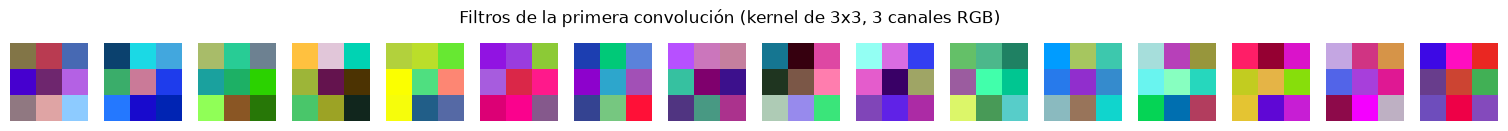

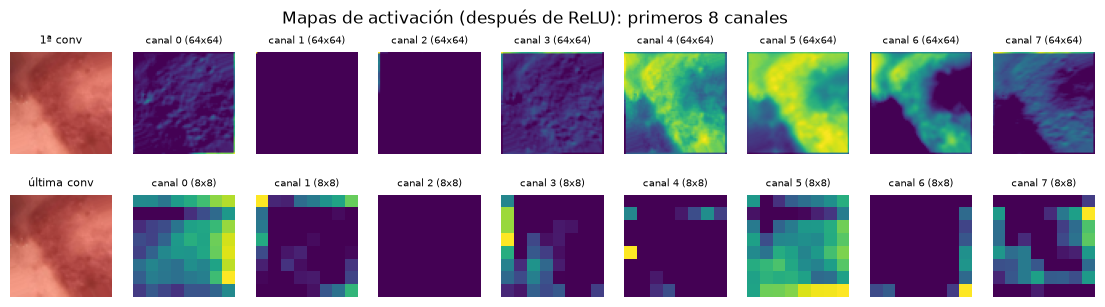

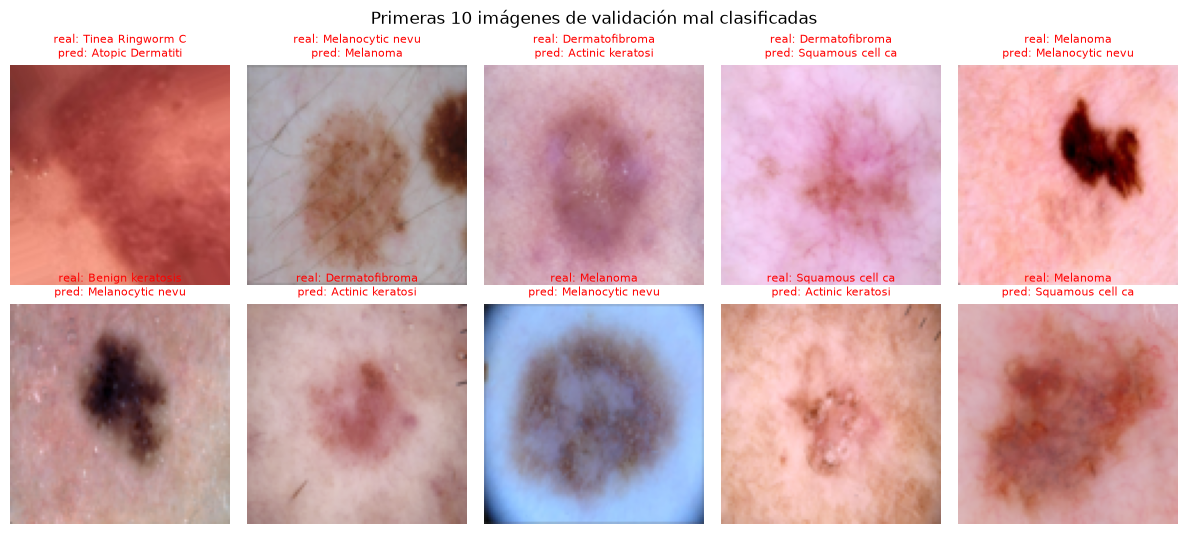

In [16]:
model = final_models["CNN final"].eval(); size = FINAL_CFG["size"]
W = model.features[0].weight.detach().cpu(); n = min(W.shape[0], 16)
fig, ax = plt.subplots(1, n, figsize=(1.2 * n, 1.5))
for i in range(n):
    w = W[i]; w = (w - w.min()) / (w.max() - w.min() + 1e-8); ax[i].imshow(w.permute(1, 2, 0), interpolation="nearest"); ax[i].axis("off")
fig.suptitle("Filtros de la primera convolución (kernel de %dx%d, 3 canales RGB)" % (W.shape[2], W.shape[3])); plt.show()

relu_pos = [i for i, l in enumerate(model.features) if isinstance(l, nn.ReLU)]
xi, yi = get_eval_batch(size, idx_va[:1])
with torch.no_grad(): a_first = model.features[:relu_pos[0] + 1](xi)[0].cpu(); a_last = model.features[:relu_pos[-1] + 1](xi)[0].cpu()
fig, ax = plt.subplots(2, 9, figsize=(14, 3.4))
for r_, (a, nm) in enumerate([(a_first, "1ª conv"), (a_last, "última conv")]):
    ax[r_, 0].imshow(X_U8[size][idx_va[0]].permute(1, 2, 0)); ax[r_, 0].set_title(nm, fontsize=8); ax[r_, 0].axis("off")
    for k in range(8): ax[r_, k + 1].imshow(a[k], cmap="viridis"); ax[r_, k + 1].axis("off"); ax[r_, k + 1].set_title(f"canal {k} ({a.shape[1]}x{a.shape[2]})", fontsize=7)
plt.suptitle("Mapas de activación (después de ReLU): primeros 8 canales"); plt.show()

_, _, pv = evaluate(model, idx_va, size)
bad = [i for i, p_ in zip(idx_va, pv) if p_ != labels[i]][:10]; pbad = [p_ for i, p_ in zip(idx_va, pv) if p_ != labels[i]][:10]
fig, ax = plt.subplots(2, 5, figsize=(12, 5.4))
for a, i, pr in zip(ax.flat, bad, pbad):
    a.imshow(X_U8[96][i].permute(1, 2, 0)); a.axis("off"); a.set_title(f"real: {class_names[labels[i]][:16]}\npred: {class_names[pr][:16]}", fontsize=8, color="red")
plt.suptitle("Primeras 10 imágenes de validación mal clasificadas"); plt.tight_layout(); plt.show()

###  ANÁLISIS 4 - Resultados finales e interpretación
**1. **Consistencia val vs. test:** ¿el resultado de test es coherente con la validación? Tengan en cuenta el error estándar binomial del test y que elegimos el mejor entre varias configuraciones sobre validación (sesgo optimista).**

La configuración final tiene 4 bloques y augmentation flips + rot90 + color.
Consiguió acc_val de 0,633 ± 0,01 (3 semillas) y test_acc de 0,671± 0,01 (5 semillas)

El test dio 3,8 puntos más que la validación. Esa diferencia está dentro del error estándar del test ±0,036. 

Al elegir la mejor configuración mirando la validación, se espera que el valor de validación de la elegida esté inflado y que el test de valores menores. Este no es el caso pero si se puede ver sesgo optimista a la hora de utilizar 4 bloques y flips + rot90 + color. Al combinarlas dio un valor menor que cada una por separado.

El test (0,671 ± 0,036) es la estimación honesta del rendimiento, porque se usó una sola vez y no se tomó ninguna decisión con él.

**2. **CNN vs. MLP en test:** ¿la diferencia supera el ruido entre semillas (± desvío) y el error estándar del test? ¿Se justifica el costo en parámetros/tiempo?**

La CNN gana por 18,1 puntos de accuracy y 19 de F1 macro.
Supera el ruido:
- entre semillas: la diferencia es 4,6 veces el desvío más grande
- error estandar del test: la diferencia es 5 veces ±0,036

A nivel cantidad de parámetros no hay costo ya que la CNN tiene 17,6 veces menos parámetros. 
A nivel tiempo la CNN tarda más (4,8 veces) ya que hace más cuentas por imagen, cada filtro se aplica en todas las posiciones, entrena con el triple de imágenes por aumentación y converge más tarde.

Se obtienen 18 puntos más de accuracy a cambio de 35 segundos extra de entrenamiento por lo que se justifica el costo. 

**3. **Matriz de confusión y reporte por clase:** ¿qué clases se confunden más y por qué (similitud clínica/visual)? En este problema, ¿es igual de grave confundir cualquier par de clases? ¿Qué métrica (recall de melanoma, F1 macro, otra) les parece más relevante que el accuracy y por qué?**

Hay varias confusiones a destacar:
1. Actinic keratosis <-> Squamous cell carcinoma: lesiones rojizas y escamosas sobre piel dañada por el sol
2. Melanoma <-> Melanocytic nevus: lesiones melanocíticas, marrones y pigmentadas
3. Dermatofibroma -> Actinic keratosis: lesiones rosadas o rojizas, sin un patrón de color muy distintivo.
4. Tinea -> Atopic Dermatitis: afecciones inflamatorias de la piel (manchas rojas, descamación)

Los errores pueden tener consecuencias muy graves para un paciente, sobretodo si se indica que un melanonma es benigno cuando no lo es. En la medicina, el recall o sensibilidad es más importante que el accuracy. En esta semilla el recall del melanoma es 0,4 lo que indica que dejaría pasar a 6 de 10, un número muy alto

Una variante  más útil sería el recall de las clases malignas en conjunto (melanoma y carcinoma escamoso) que mide cuántos cánceres detecta el modelo. 
El F1 macro es útil como complemento, porque hace que todas las clases pesen lo mismo y muestra si alguna queda descuidada. Pero también trata todos los errores como si costaran lo mismo cuando no es así. 

**4. **Filtros, mapas de activación y errores:** ¿qué detectan las primeras capas y qué cambia en la última (tamaño espacial, nivel de abstracción)? ¿Qué patrones comunes tienen las imágenes mal clasificadas?**

Los filtros de la primera convolución son de 3×3 con 3 canales, y cada uno se dibuja como un cuadro de colores. Muestran contraste de color entre sus casillas lo que indica que detectan cambios de color locales. 

Los mapas de la primera convolución conservan la forma de la imagen y ven la lesión. Los canales 4 y 5 se activan en la zona rojo oscura y siguen su contorno, así que separan la lesión de la piel más clara. Los canales 0 y 3 marcan una textura fina, el granulado de la piel. Los canales 6 y 7 se activan en una sola región. Y los canales 1 y 2 están completamente apagados: después de la ReLU valen 0 en toda la imagen, porque lo que buscan no aparece en esta foto. Son detectores simples y locales: color, contraste, textura.

En la última capa el mapa pasa de 64x64 a 8x8. ya no se reconoce la imagen y los mapas tienen pocas casillas activas. 

Los patrones comunes de las imágenes mal clasificadas son: Lesiones de bajo contraste, rosadas sin borde definido. Además dos melanomas, un lunar y una queratosis benigna se confunden dentro del grupo, lo que puede deberse a que el modelo se guía por oscuridad de la mancha. 

**5. **Sesgos y limitaciones:** retomen el EDA (resoluciones y color por clase, duplicados). ¿Qué sesgos del dataset podrían inflar o distorsionar los números? Tamaño del dataset, una sola partición, pocas semillas, validación chica: ¿qué harían con más tiempo?**



## Declaración de uso de IA
Completen (obligatorio): ¿usaron herramientas de IA? ¿Cuáles, para qué parte (código, redacción del análisis, ideas) y qué modificaron o verificaron por su cuenta? Si no usaron, aclaren que no.

Use ClaudeIA para:
 - escribir el código que imprime la loss por época después de la sección 7 con el objetivo de verificar la brecha.
 - consultar acerca de características de las lesiones de la piel y otras cuestiones de criterio a la hora de analizar valores como la varianza. 
- consultar acerca de comparaciones estadísticas, en que casos son significativas o no. 